# CACHE — Demonstration notebook

Training-free analysis of **collagen-like stromal architecture**, not collagen-specific segmentation. The notebook has separate synthetic and real-world sections. Images are used for qualitative evaluation; results are not diagnostic.

In [1]:
from pathlib import Path
import numpy as np
from PIL import Image
from IPython.display import display, Markdown
from cache import analyze, plot_review

OUTPUT = Path("cache_output/notebook")
OUTPUT.mkdir(parents=True, exist_ok=True)

def run_cache(image_path, output_name, mpp=None, max_side=900):
    im = Image.open(image_path).convert("RGB")
    im.thumbnail((max_side, max_side))
    rgb = np.asarray(im)
    result = analyze(rgb, mpp=mpp, scales_um=(1.5, 3, 6, 12), window_um=30)
    out = OUTPUT / f"{output_name}.png"
    plot_review(result, out, title=Path(image_path).stem)
    display(Image.open(out))
    print(result["features"])
    return result

## 1. Synthetic H&E-like image

Synthetic geometry is useful for debugging orientation recovery, but does not validate collagen identification in actual tissue.

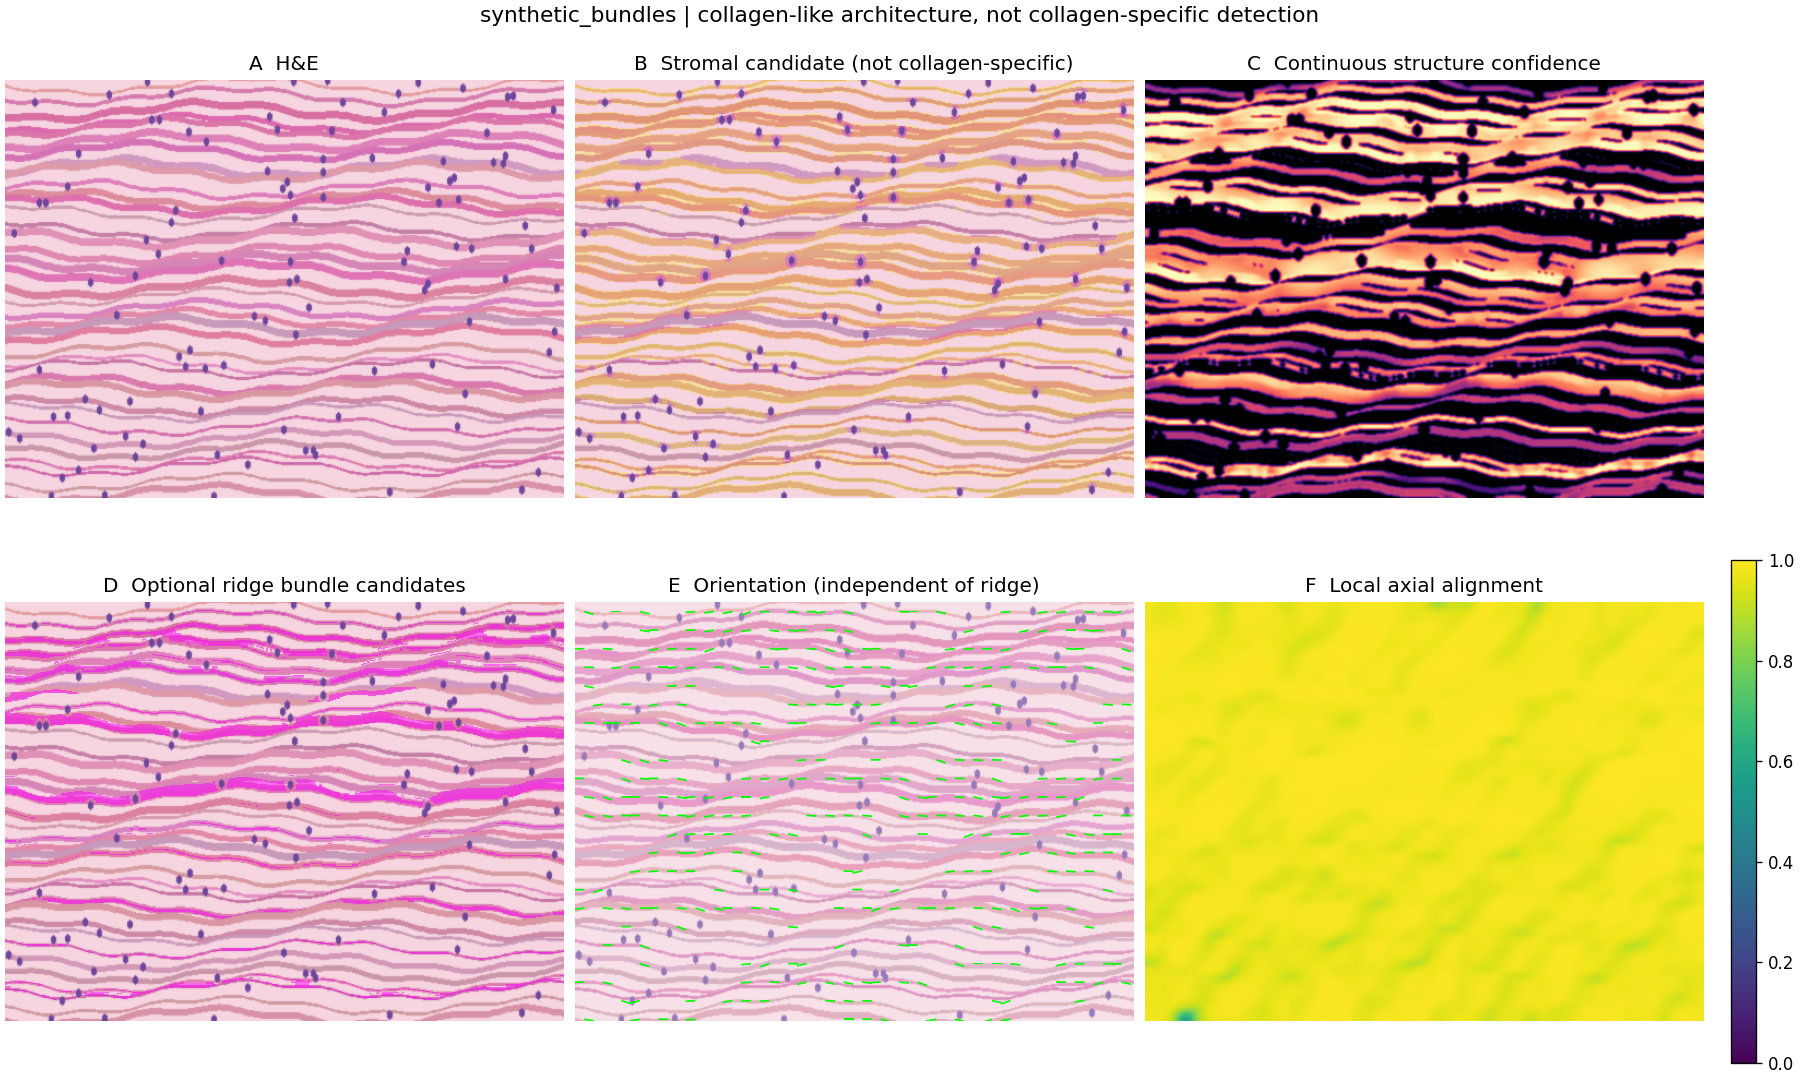

{'candidate_fraction': 0.5070241292317709, 'orientation_coverage': 0.9961278025781211, 'ridge_coverage': 0.2885489291267493, 'global_alignment': 0.954262252464035, 'dominant_orientation_deg': 0.7847865544703411, 'mean_local_alignment': 0.9807403258006961, 'mpp_um': None}


In [2]:
synthetic_path = Path("examples/synthetic_bundles.png")
synthetic_result = run_cache(synthetic_path, "synthetic")

## 2. Real-world H&E images

These files were supplied in `collagen_examples.zip`. The first three are named histopathology images and five are labeled `example1`–`example5`; their original source, license, and physical pixel size should be verified before public redistribution or biological measurement. **MPP is intentionally left as `None`**; these demonstrations use pixel-scale parameters, not calibrated micrometers. Images are resized for notebook responsiveness.

In [3]:
real_dir = Path("examples/real_images")
real_paths = sorted([*real_dir.glob("*.jpg"), *real_dir.glob("*.png")])
print(f"Found {len(real_paths)} real H&E examples")
for i, p in enumerate(real_paths):
    print(f"{i}: {p.name}")

Found 8 real H&E examples
0: Histopathology of collagenous colitis.jpg
1: Histopathology of moderate fibrosis.jpg
2: Histopathology of stromal fibrosis of the breast.jpg
3: example1.png
4: example2.png
5: example3.png
6: example4.png
7: example5.png


### Histopathology of collagenous colitis

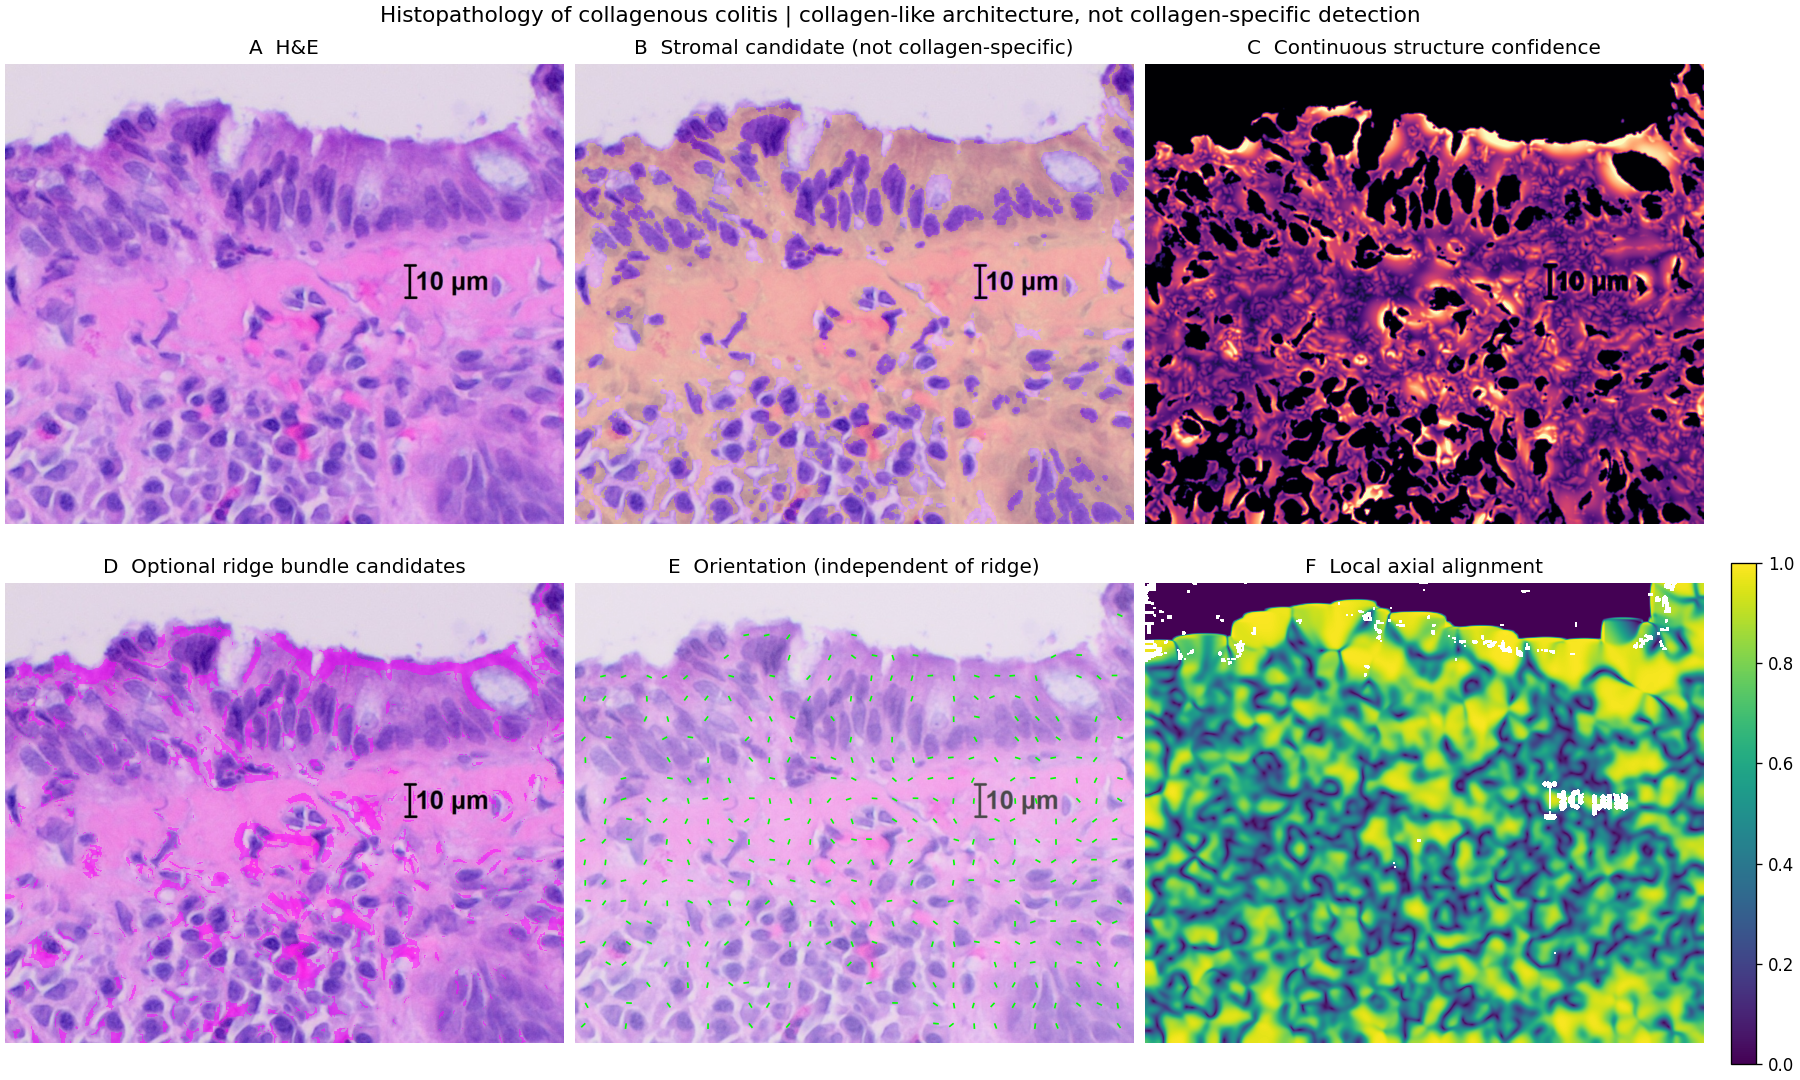

{'candidate_fraction': 0.6167475292003594, 'orientation_coverage': 0.9948793776586446, 'ridge_coverage': 0.29086300332148474, 'global_alignment': 0.0698116132461001, 'dominant_orientation_deg': 52.59181680712196, 'mean_local_alignment': 0.5752624026789646, 'mpp_um': None}


In [4]:
real_results = {}
for p in real_paths:
    display(Markdown(f"### {p.stem}"))
    real_results[p.name] = run_cache(p, "real_" + p.stem.replace(" ", "_"), mpp=None)
    break

## 3. Qualitative review checklist

- Does the candidate overlay track stromal collagen rather than nuclei, epithelium, or smooth muscle?
- Do orientation vectors follow visible collagen bundles?
- Does ridge detection fail on broad or interwoven bundles?
- Are arrows, scale bars, borders, and annotations excluded?
- Does local alignment reflect collagen organization or other directional textures?

**Interpretation:** Candidate fraction is not collagen fraction; orientation coverage is not sensitivity. Do not use screenshots or unknown MPP for physical-size claims.